<h1> Final Project - Workshop </h1>

In [3]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV, RepeatedKFold


random_seed = 42

In [1]:
#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True

NameError: name 'plt' is not defined

<h3> Dataset Downloads </h3>

In [6]:
d15 = pd.read_csv('flights_2015.csv', low_memory = False)
d15.info()

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  CANCELLED

<h2> Dataset 1: 2015 Flight Delays and Causes </h2>

<h3> Data Dictionary </h3>

ALL TIMES ARE IN MILITARY TIME, ARRIVAL AND DEPARTURE TIMES ARE ADJUSTED WITH LOCAL TIMEZONES

- YEAR: Year of the flight trip
- MONTH: Month of the flight trip
- DAY: Day of the flight trip
- DAY_OF_WEEK: Day of week of the flight trip
- AIRLINE: Airline identifier
- FLIGHT_NUMBER: Flight identifier
- TAIL_NUMBER: Aircrage identifier
- ORIGIN_AIRPORT: Starting airport
- DESTINATION_AIRPORT: Destination airport
- SCHEDULED_DEPARTURE: Planned departure time
- DEPARTURE_TIME: WHEELS_OFF - TAXI_OUT
- DEPARTURE_DELAY: Total delay on departure (minutes)
- TAXI_OUT: Time duration elapsed between the origin airport gate and wheels off (minutes)
- WHEELS_OFF: The time point that the aircraft's wheels leave the ground
- SCHEDULED_TIME: Planned time amount for the flight trip
- ELAPSED_TIME: TAXI_OUT + AIR_TIME + TAXI_IN (minutes)
- AIR TIME: Time duration between WHEELS_OFF and WHEELS_ON times (minutes)
- DISTANCE: Distance between 2 airports (miles)
- WHEELS_ON: The time point that the aircraft's wheels touch on the ground
- TAXI_IN: The time duration elapsed between wheels-on and gate arrival at the destination airport (minutes)
- SCHEDULED_ARRIVAL: Arrival time
- ARRIVAL_TIME: WHEELS_ON + TAXI_IN
- ARRIVAL_DELAY: WHEELS_ON + TAXI_IN - SCHEDULED_ARRIVAL (minutes; if this value is positive, that means the flight got in early)
- DIVERTED: Aircraft landed on airport that out of schedule (0 or 1)
- CANCELLED: Flight Cancelled (1 = cancelled)
- CANCELLATION_REASON: Reason for Cancellation of flight: A - Airline/Carrier; B - Weather; C - National Air System; D - Security
- AIR_SYSTEM_DELAY: Delay caused by air system (minutes)
- SECURITY_DELAY: Delay caused by security (minutes)
- AIRLINE_DELAY: Delay caused by the airline (minutes)
- LATE_AIRCRAFT_DELAY: Delay caused by aircraft (minutes)
- WEATHER_DELAY: Delay caused by weather (minutes)

<h3> Preprocessing </h3>

In [11]:
all15 = d15.copy()

In [12]:
all15.head(5)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


<h3> Duplicate Rows, Missing Values </h3>

In [14]:
dupes_15 = all15[all15.duplicated()]
dupes_15

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY


<h3> Dummy-ing the null values in delay reason columns </h3>

In [17]:
all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']] = all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']].fillna(0)

<h3> Adding Full Names for Airlines (Important Later)</h3>

In [20]:
#mapping the airline abbreviations to full names

airline_map = {'UA': 'United Air Lines Inc.',
 'AA': 'American Airlines Inc.',
 'US': 'US Airways Inc.',
 'F9': 'Frontier Airlines Inc.',
 'B6': 'JetBlue Airways',
 'OO': 'Skywest Airlines Inc.',
 'AS': 'Alaska Airlines Inc.',
 'NK': 'Spirit Air Lines',
 'WN': 'Southwest Airlines Co.',
 'DL': 'Delta Air Lines Inc.',
 'EV': 'Atlantic Southeast Airlines',
 'HA': 'Hawaiian Airlines Inc.',
 'MQ': 'American Eagle Airlines Inc.',
 'VX': 'Virgin America'}

In [21]:
# Create new column 'Category' based on 'ID'
all15['AIRLINE_FULL'] = all15['AIRLINE'].map(airline_map)

In [22]:
all15.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,US Airways Inc.
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.


<h3> What's going on w/ the canceled flights? </h3>

In [24]:
section = all15[all15['CANCELLATION_REASON'].notnull() & all15['CANCELLED'] == 1]
len(section)

89884

All cancelled flights will have a non-null cancellation reason.

In [26]:
len(all15) - len(section) #every flight with a null cancellation reason wasn't cancelled

5729195

In [27]:
all15['CANCELLATION_REASON'] = all15['CANCELLATION_REASON'].fillna('Not Canceled')

<h3> Null Tail Numbers </h3>

In [30]:
section = all15[all15['TAIL_NUMBER'].isnull()]
section.info()

<class 'pandas.DataFrame'>
Index: 14721 entries, 297 to 5818157
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 14721 non-null  int64  
 1   MONTH                14721 non-null  int64  
 2   DAY                  14721 non-null  int64  
 3   DAY_OF_WEEK          14721 non-null  int64  
 4   AIRLINE              14721 non-null  str    
 5   FLIGHT_NUMBER        14721 non-null  int64  
 6   TAIL_NUMBER          0 non-null      str    
 7   ORIGIN_AIRPORT       14721 non-null  str    
 8   DESTINATION_AIRPORT  14721 non-null  str    
 9   SCHEDULED_DEPARTURE  14721 non-null  int64  
 10  DEPARTURE_TIME       0 non-null      float64
 11  DEPARTURE_DELAY      0 non-null      float64
 12  TAXI_OUT             0 non-null      float64
 13  WHEELS_OFF           0 non-null      float64
 14  SCHEDULED_TIME       14721 non-null  float64
 15  ELAPSED_TIME         0 non-null      float64
 16

Flights with no tail number appear to be cancelled flights.

In [32]:
all15['TAIL_NUMBER'] = all15['TAIL_NUMBER'].fillna('No Tail')

<h3> Null Values for Scheduled Time </h3>

In [35]:
section = all15[all15['SCHEDULED_TIME'].isnull()][['SCHEDULED_TIME', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON']]
section

,SCHEDULED_TIME,DIVERTED,CANCELLED,CANCELLATION_REASON
483174,NaN,0,1,B
619941,NaN,0,1,B
1720237,NaN,1,0,Not Canceled
1820960,NaN,0,1,B
2031482,NaN,0,1,B
2034453,NaN,0,1,C


Of the 6 flights with null scheduled time, 5 were canceled and 1 was diverted. I'm down to drop them.

In [37]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3>EQUAL Null Values for (Presumedly) Canceled Flights </h3>

In [40]:
# pulling the null values we're seeing for cancelled flights

cancel = all15[all15['CANCELLED'] == 1][['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
                                         'WHEELS_OFF', 'ELAPSED_TIME', 'AIR_TIME',
                                         'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME',
                                         'ARRIVAL_DELAY']]
cancel.head()

,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,ELAPSED_TIME,AIR_TIME,WHEELS_ON,TAXI_IN,ARRIVAL_TIME,ARRIVAL_DELAY
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
#finding values in this section that aren't null

section = cancel.notnull()
len(section)

89879

So here's what we have at this point:

- cancelled flights have no value departure time or departure delay, or most of the other variables pertaining to the flight

ngl I think we need to just separate the cancelled and non-cancelled flights

In [43]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3> Creating a "TOTAL_DELAY" Column</h3>

In [46]:
all15['TOTAL_DELAY'] = all15.ELAPSED_TIME - all15.SCHEDULED_TIME

In [47]:
trips = all15[['SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 
               'DEPARTURE_DELAY', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'SCHEDULED_ARRIVAL', 
               'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 
               'WEATHER_DELAY', 'TOTAL_DELAY']]
trips.head(15)

,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,SCHEDULED_TIME,ELAPSED_TIME,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,TOTAL_DELAY
0,5,2354.0,-11.0,205.0,194.0,430,408.0,-22.0,0.0,0.0,0.0,0.0,0.0,-11.0
1,10,2.0,-8.0,280.0,279.0,750,741.0,-9.0,0.0,0.0,0.0,0.0,0.0,-1.0
2,20,18.0,-2.0,286.0,293.0,806,811.0,5.0,0.0,0.0,0.0,0.0,0.0,7.0
3,20,15.0,-5.0,285.0,281.0,805,756.0,-9.0,0.0,0.0,0.0,0.0,0.0,-4.0
4,25,24.0,-1.0,235.0,215.0,320,259.0,-21.0,0.0,0.0,0.0,0.0,0.0,-20.0
5,25,20.0,-5.0,217.0,230.0,602,610.0,8.0,0.0,0.0,0.0,0.0,0.0,13.0
6,25,19.0,-6.0,181.0,170.0,526,509.0,-17.0,0.0,0.0,0.0,0.0,0.0,-11.0
7,30,44.0,14.0,273.0,249.0,803,753.0,-10.0,0.0,0.0,0.0,0.0,0.0,-24.0
8,30,19.0,-11.0,195.0,193.0,545,532.0,-13.0,0.0,0.0,0.0,0.0,0.0,-2.0
9,30,33.0,3.0,221.0,203.0,711,656.0,-15.0,0.0,0.0,0.0,0.0,0.0,-18.0


<h3>Splitting up Cancelled and not cancelled flights</h3>

In [49]:
all15_nc = all15[all15.CANCELLED == 0]
all15_c = all15[all15.CANCELLED == 1]

In [50]:
print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 15186
AIR_TIME 15186
DISTANCE 0
WHEELS_ON 2628
TAXI_IN 2628
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 2628
ARRIVAL_DELAY 15186
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0
TOTAL_DELAY 15186


In [51]:
print('Checking the columns for null values:')
print()

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 89879
AIR_TIME 89879
DISTANCE 0
WHEELS_ON 89879
TAXI_IN 89879
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 89879
ARRIVAL_DELAY 89879
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0
TOTAL_DELAY 89879


In [52]:
# dropping nulls from non-cancelled flights (15186 out of over 5 million rows, negligible)

all15_nc = all15_nc.dropna()

print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 0
AIR_TIME 0
DISTANCE 0
WHEELS_ON 0
TAXI_IN 0
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 0
ARRIVAL_DELAY 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0
TOTAL_DELAY 0


In [53]:
#keeping just the cancellation info for the canceled flights

all15_c = all15_c.drop(['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'ELAPSED_TIME',
                       'AIR_TIME', 'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME', 'ARRIVAL_DELAY',
                       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY',
                       'TOTAL_DELAY'], axis = 1)

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
SCHEDULED_TIME 0
DISTANCE 0
SCHEDULED_ARRIVAL 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIRLINE_FULL 0


First preprocessing steps:

- Dummied down the variables for different types of delays
- Labeled flights with no tail numbers
- Dropped rows with no SCHEDULED_TIME (projected trip time)
- Created a TOTAL_DELAY column (elapsed_time - scheduled time)
- Split up cancelled and non-cancelled flights (instead of merging them with another one)
- Non-cancelled: dropped nulls, 15186 rows
- Cancelled: dropped irrelevant columns (cancelled flights aren't delayed fam)

<h3> Encoding Categorical Variables</h3>

In [56]:
#for non-cancelled first

cat_15nc = all15_nc.select_dtypes(include=['object', 'str'])
cat_15nc

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
0,AS,N407AS,ANC,SEA,Not Canceled,Alaska Airlines Inc.
1,AA,N3KUAA,LAX,PBI,Not Canceled,American Airlines Inc.
2,US,N171US,SFO,CLT,Not Canceled,US Airways Inc.
3,AA,N3HYAA,LAX,MIA,Not Canceled,American Airlines Inc.
4,AS,N527AS,SEA,ANC,Not Canceled,Alaska Airlines Inc.
...,...,...,...,...,...,...
5819074,B6,N657JB,LAX,BOS,Not Canceled,JetBlue Airways
5819075,B6,N828JB,JFK,PSE,Not Canceled,JetBlue Airways
5819076,B6,N913JB,JFK,SJU,Not Canceled,JetBlue Airways
5819077,B6,N527JB,MCO,SJU,Not Canceled,JetBlue Airways


In [57]:
cat_15c = all15_c.select_dtypes(include=['object', 'str'])
cat_15c

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
32,AS,N431AS,ANC,SEA,A,Alaska Airlines Inc.
42,AA,N3BDAA,PHX,DFW,B,American Airlines Inc.
68,OO,N746SK,MAF,IAH,B,Skywest Airlines Inc.
82,MQ,N660MQ,SGF,DFW,B,American Eagle Airlines Inc.
90,OO,N583SW,RDD,SFO,A,Skywest Airlines Inc.
...,...,...,...,...,...,...
5818090,UA,No Tail,IAH,TPA,A,United Air Lines Inc.
5818157,UA,No Tail,SFO,LAX,A,United Air Lines Inc.
5818318,AA,N880AA,MIA,SAN,A,American Airlines Inc.
5818777,NK,N522NK,FLL,IAG,A,Spirit Air Lines


In [58]:
len(pd.unique(cat_15c.TAIL_NUMBER))

3846

In [59]:
#encoding the cancellation reasons for cancelled flights

cancels = pd.get_dummies(all15_c['CANCELLATION_REASON'], prefix = 'CANCELLATION', dtype = int)
all15_c = all15_c.join(cancels)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_A,CANCELLATION_B,CANCELLATION_C,CANCELLATION_D
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [60]:
#renaming them

all15_c['CANCELLATION_AIRLINE'] = all15_c['CANCELLATION_A']
all15_c['CANCELLATION_WEATHER'] = all15_c['CANCELLATION_B']
all15_c['CANCELLATION_SYSTEM'] = all15_c['CANCELLATION_C']
all15_c['CANCELLATION_SECURITY'] = all15_c['CANCELLATION_D']

all15_c = all15_c.drop(['CANCELLATION_A', 'CANCELLATION_B', 'CANCELLATION_C', 'CANCELLATION_D'], axis = 1)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_AIRLINE,CANCELLATION_WEATHER,CANCELLATION_SYSTEM,CANCELLATION_SECURITY
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [61]:
all15_nc = all15_nc.drop(['CANCELLED', 'CANCELLATION_REASON'], axis = 1)
all15_nc.info()

<class 'pandas.DataFrame'>
Index: 5714008 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  AIR_SYSTEM_DEL

In [62]:
all15_c.info()

<class 'pandas.DataFrame'>
Index: 89879 entries, 32 to 5818843
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   YEAR                   89879 non-null  int64  
 1   MONTH                  89879 non-null  int64  
 2   DAY                    89879 non-null  int64  
 3   DAY_OF_WEEK            89879 non-null  int64  
 4   AIRLINE                89879 non-null  str    
 5   FLIGHT_NUMBER          89879 non-null  int64  
 6   TAIL_NUMBER            89879 non-null  str    
 7   ORIGIN_AIRPORT         89879 non-null  str    
 8   DESTINATION_AIRPORT    89879 non-null  str    
 9   SCHEDULED_DEPARTURE    89879 non-null  int64  
 10  SCHEDULED_TIME         89879 non-null  float64
 11  DISTANCE               89879 non-null  int64  
 12  SCHEDULED_ARRIVAL      89879 non-null  int64  
 13  DIVERTED               89879 non-null  int64  
 14  CANCELLED              89879 non-null  int64  
 15  CANCELLATION_RE

Second set of preprocessing steps:

- Encoded the 4 cancellation reasons

We kept the original variables because we can use those for barplots later

<h3>Creating DATE Column</h3>

In [65]:
all15_nc['DATE'] = pd.to_datetime(all15_nc[['YEAR', 'MONTH', 'DAY']])
all15_c['DATE'] = pd.to_datetime(all15_c[['YEAR', 'MONTH', 'DAY']])

In [66]:
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL,TOTAL_DELAY,DATE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,-11.0,2015-01-01
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,-1.0,2015-01-01
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0.0,0.0,0.0,0.0,0.0,US Airways Inc.,7.0,2015-01-01
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,-4.0,2015-01-01
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,-20.0,2015-01-01


Last set of preprocessing (2015):

- Changed CANCELLATION_REASON from coded letter to the actual reason (below)
- Created datetime column from YEAR, MONTH, and DAY

Non-Cancelled Flights: 5714008 flights
Cancelled Flights: 89879 flights

<h3>EDA - Multivariate Analysis</h3>

Keeping the correlation matrix for reference

In [70]:
number15= all15_nc.drop(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'AIRLINE', 'AIRLINE_FULL',
                         'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE',
                        'DEPARTURE_TIME', 'WHEELS_OFF', 'WHEELS_ON', 'SCHEDULED_ARRIVAL',
                        'ARRIVAL_TIME', 'DATE', 'DIVERTED'], axis =1) #creating df of numeric columns only to run correlation matrix

corrs = number15.corr()

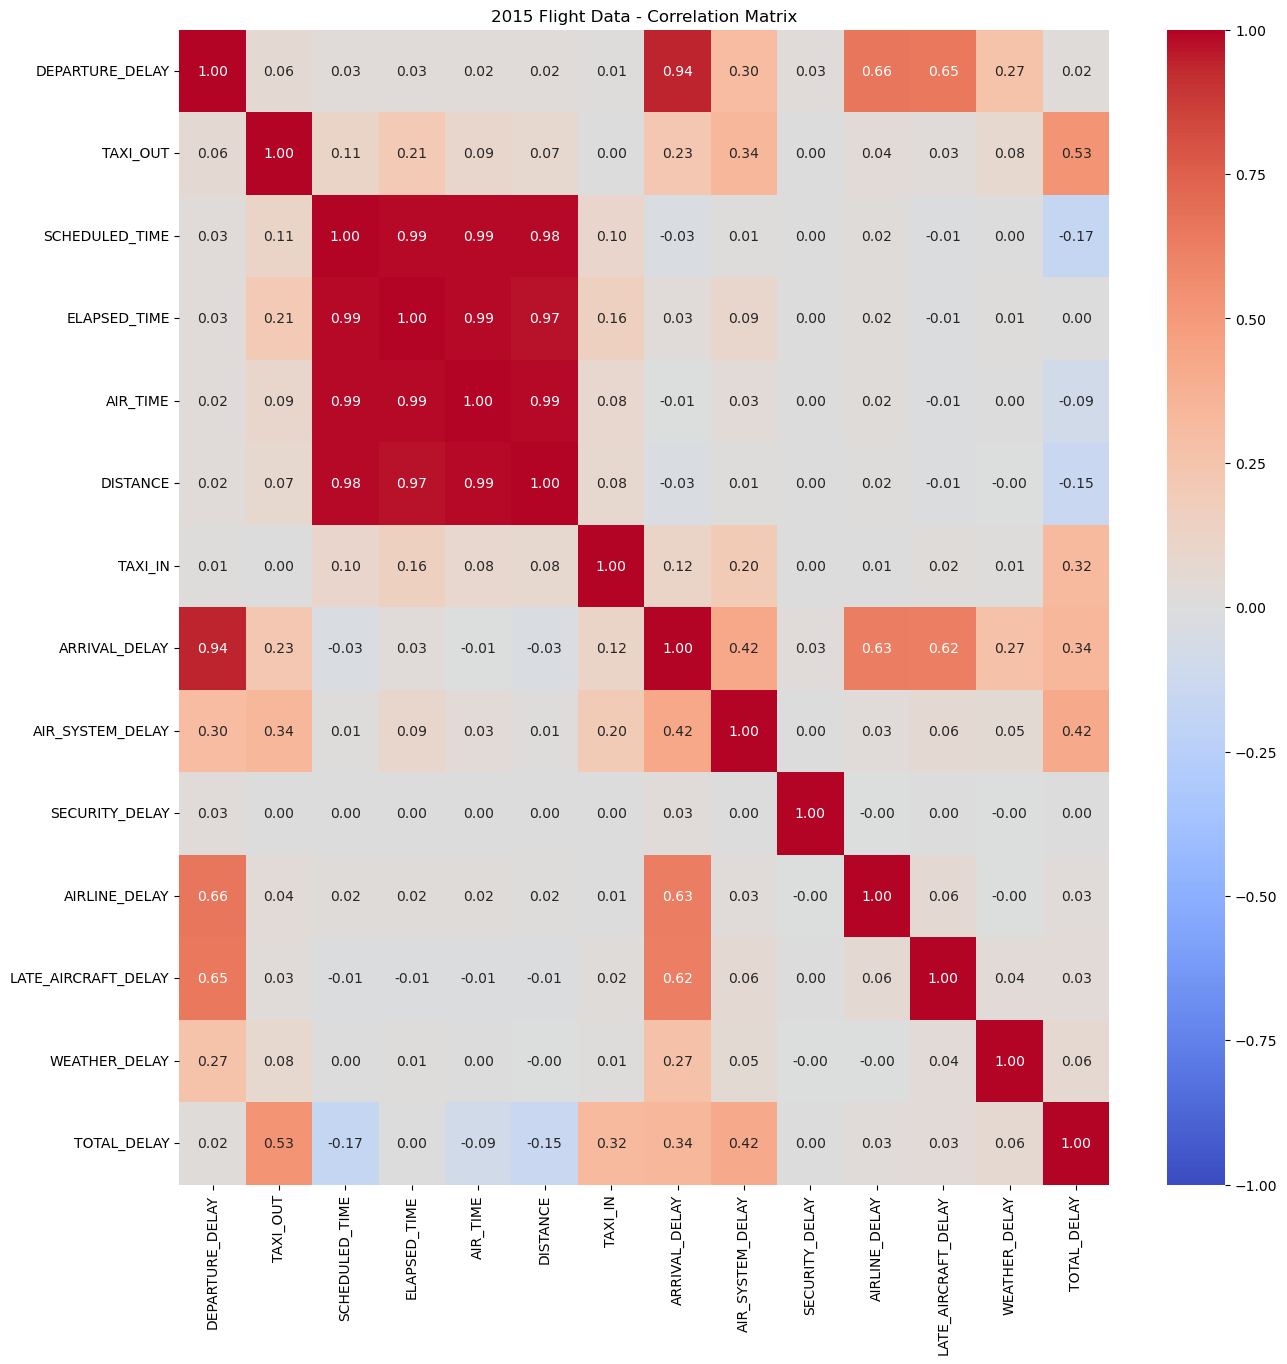

In [71]:
plt.figure(figsize=(15, 15))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2015 Flight Data - Correlation Matrix')
plt.show()

What we know:

- Arrival and Departure delay seem to be almost perfectly correlated (makes sense)
- Our created target variable TOTAL_DELAY: 2 highest positive correlations are with TAXI_OUT (0.53) and AIR_SYSTEM_DELAY (0.42)
- The original target variables: ARRIVAL_DELAY highly correlated with AIRLINE_DELAY (0.63) and LATE_AIRCRAFT_DELAY (0.62), DEPARTURE_DELAY highly correlated with AIRLINE_DELAY (0.66) and LATE_AIRCRAFT_DELAY (0.65)
- Distance not highly correlated with anything
- None of the encoded airline variables are super strongly correlated with our targets

<h3>Heatmaps</h3>

In [181]:
pivot = all15_nc.pivot_table(index = ["AIRLINE_FULL"], columns = ["DAY_OF_WEEK"], values = "DEPARTURE_DELAY", aggfunc = "mean")

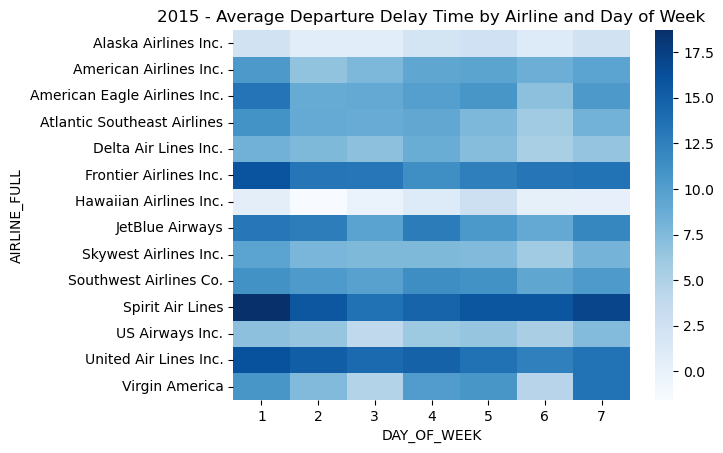

In [183]:
ax1 = sns.heatmap(pivot, cmap = "Blues")
ax1.set_title("2015 - Average Departure Delay Time by Airline and Day of Week");

In [165]:
pivot2 = all15_nc.pivot_table(index = ["AIRLINE_FULL"], columns = ["DAY_OF_WEEK"], values = "TOTAL_DELAY", aggfunc = "mean")

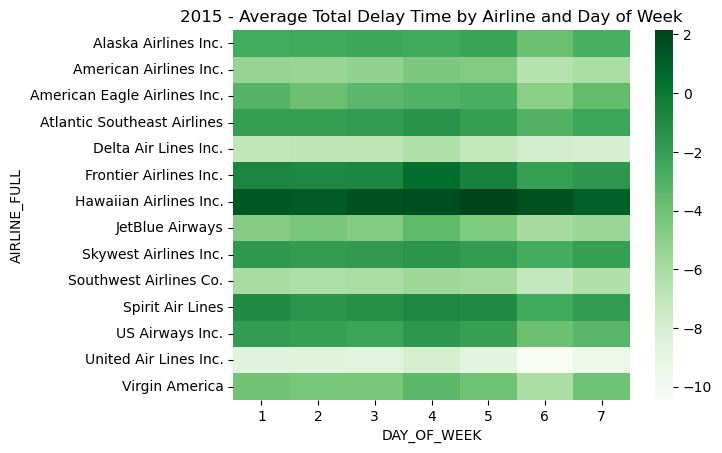

In [173]:
ax2 = sns.heatmap(pivot2, cmap = "Greens")
ax2.set_title("2015 - Average Total Delay Time by Airline and Day of Week");

<h3>Bubble Plots</h3>

/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


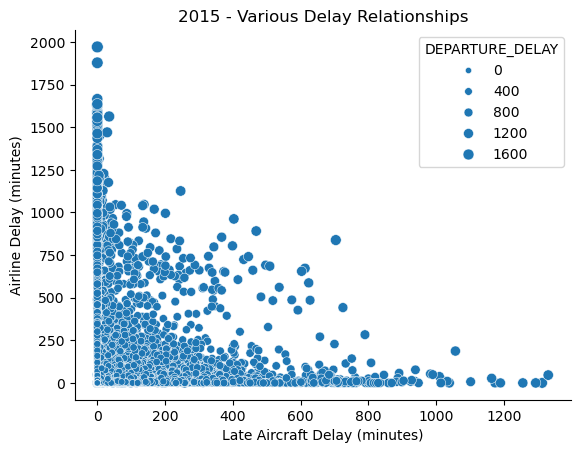

In [199]:
ax3 = sns.scatterplot(data = all15_nc, x = "LATE_AIRCRAFT_DELAY", y = "AIRLINE_DELAY", size = "DEPARTURE_DELAY")
ax3.set_xlabel("Late Aircraft Delay (minutes)")
ax3.set_ylabel("Airline Delay (minutes)")
ax3.set_title('2015 - Various Delay Relationships')
plt.show();

/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


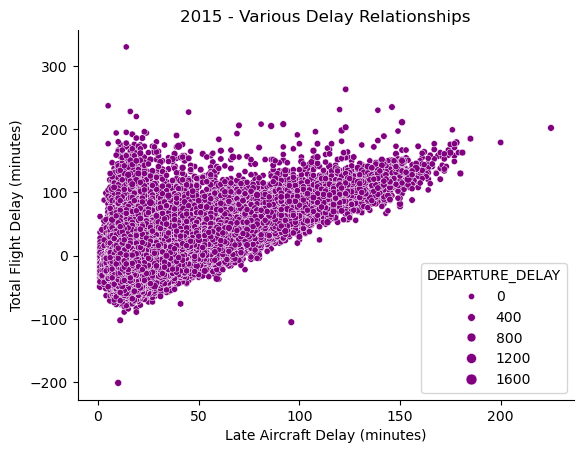

In [202]:
ax4 = sns.scatterplot(data = all15_nc, x = "TAXI_OUT", y = "TOTAL_DELAY", size = "DEPARTURE_DELAY", color = 'purple')
ax4.set_xlabel("Late Aircraft Delay (minutes)")
ax4.set_ylabel("Total Flight Delay (minutes)")
ax4.set_title('2015 - Various Delay Relationships')
plt.show();

<h3>PCA</h3>

In [205]:
from sklearn.decomposition import PCA

In [221]:
pca = PCA(n_components = 3)
pca.fit(number15)
print('Explained variance ratios of', len(pca.components_), 'principal components:', pca.explained_variance_ratio_)
print()
print(pca.components_)

Explained variance ratios of 3 principal components: [0.98738865 0.00833554 0.00151241]

[[ 1.43116762e-03  1.07094531e-03  1.19421678e-01  1.16438851e-01
   1.14672707e-01  9.79293150e-01  6.95198750e-04 -1.55165862e-03
   2.11570520e-04  5.13229064e-06  5.43286483e-04 -4.78896082e-04
  -3.74852526e-05 -2.98282640e-03]
 [ 6.33772892e-01  2.50768867e-02  1.05454911e-03  4.68505568e-02
   1.43899471e-02 -7.17078482e-03  7.38372300e-03  6.79568896e-01
   8.33919816e-02  4.05999135e-04  2.58272273e-01  2.36966460e-01
   3.83504655e-02  4.57960077e-02]
 [-2.06478477e-01  2.11831781e-01  2.91037790e-01  6.53620963e-01
   3.66290267e-01 -1.54750817e-01  7.54989151e-02  1.56104689e-01
   2.34864709e-01  5.98560932e-05 -1.32371822e-01 -8.89893824e-02
   1.77774796e-02  3.62583173e-01]]


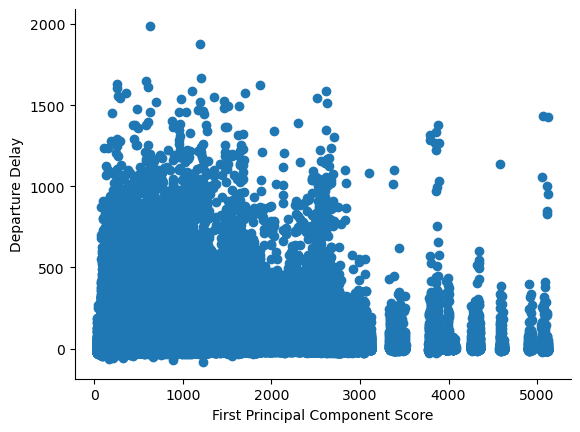

In [229]:
first_principal_component_score = number15.dot(pca.components_[0])
plt.scatter(first_principal_component_score, number15.DEPARTURE_DELAY)
plt.xlabel("First Principal Component Score")
plt.ylabel("Departure Delay");

<h3>Linear Regression</h3>

In [227]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error

In [239]:
#standard scaling the numerical data

sc = StandardScaler()

sc15 = sc.fit_transform(number15)
df_scaled = pd.DataFrame(sc15, columns=number15.columns)
df_scaled.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,TOTAL_DELAY
0,-0.550149,0.555534,0.837906,0.767996,0.768209,1.024449,-0.610268,-0.672426,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.474426
1,-0.468826,-0.457700,1.833737,1.913378,2.069593,2.473529,-0.610268,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,0.301768
2,-0.306179,-0.007374,1.913403,2.102029,2.111126,2.417669,0.635517,0.015099,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,0.922723
3,-0.387502,-0.119955,1.900125,1.940328,2.000370,2.493245,0.101609,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,0.068909
4,-0.279071,-0.570282,1.236238,1.050973,1.183544,1.024449,-0.432298,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-1.173001


In [261]:
#predicting the departure delay time from the different special delay types

delay_types = ['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

lr1 = LinearRegression()

lr1.fit(df_scaled[delay_types], df_scaled.DEPARTURE_DELAY)

coeff_df1 = pd.Series(lr1.coef_, index=df_scaled[delay_types].columns)
print(coeff_df1)
print()

y_pred1 = lr1.predict(df_scaled[delay_types])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

AIR_SYSTEM_DELAY       0.241949
SECURITY_DELAY         0.026443
AIRLINE_DELAY          0.618079
LATE_AIRCRAFT_DELAY    0.594337
WEATHER_DELAY          0.234371
dtype: float64

RMSE (DEPARTURE_DELAY): 0.26229558917903384


In [263]:
#predicting the total delay time from the different special delay types

lr2 = LinearRegression()

lr2.fit(df_scaled[delay_types], df_scaled.TOTAL_DELAY)

coeff_df2 = pd.Series(lr2.coef_, index=df_scaled[delay_types].columns)
print(coeff_df2)
print()

y_pred1 = lr1.predict(df_scaled[delay_types])
print('RMSE (TOTAL_DELAY):', root_mean_squared_error(y_pred1, df_scaled.TOTAL_DELAY))

AIR_SYSTEM_DELAY       0.417761
SECURITY_DELAY         0.003401
AIRLINE_DELAY          0.015129
LATE_AIRCRAFT_DELAY    0.006267
WEATHER_DELAY          0.042200
dtype: float64

RMSE (TOTAL_DELAY): 1.2750554863464334


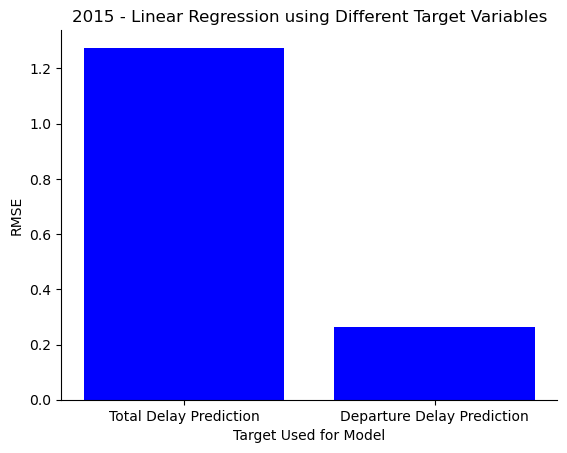

In [274]:
#bar chart of RMSEs
model_types = ['Total Delay Prediction', 'Departure Delay Prediction']
RMSEs = [root_mean_squared_error(y_pred1, df_scaled.TOTAL_DELAY), root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY)]

plt.bar(model_types, RMSEs, color = 'blue')
plt.xlabel('Target Used for Model')
plt.ylabel('RMSE')
plt.title('2015 - Linear Regression using Different Target Variables');

Findings from multivariate analysis (2015):

- 1 Principal Component looks to be able to explain 98.7% of the variation in the data (amazing way to reduce dimensionality, but doesn't seem to show the relationship between variables and targets)
- Made a pivot with the day of week as the columns and the individual airlines as rows, color scale as average DEPARTURE_DELAY; Frontier (10+ minutes), Spirit (13+ minutes) and United (10+) clearly have the worst average departure delay times for flights, regardless of day. Also, Alaskan and Hawaiian Airlines appears to have the closest departure delay times to 0. If I had to eyeball it, it appears that Day 1 (Sunday) has the highest average delay times, regardless of airline
- Made a pivot with the day of week as the columns and the individual airlines as rows, color scale as average TOTAL_DELAY; When we switch the target variable we use, the perpetrating airline changes. Hawaiian Airlines (which we saw clearly has one of the lowest average departure delay times regardless of day of week) now has the clear highest average total flight delay times (around 1-2 minutes), which isn't really that much when putting it into perspective. Frontier and Spirit are close behind, but the average total delay times are close 0, indicating that flights from these airlines (on average) usually make up for delayed departures really well.
- Bubble Plot with late aircraft delay on x-axis, airline delay on the y-axis, bubble size is departure delay --> it looks as if the points on the far-right (longer late aircraft delay) and top (high airline delay) have the biggest bubbles, which makes sense
- Linear regressions (using the 5 special delay types, rest of the variables had coefficients close to 0) --> highest positive coefficients for predicting DEPARTURE delay were airline delay and late aircraft delay (lines up with correlation as well). Highest positive coefficients for predicting TOTAL delay was air system delay with weather wayyyyy behind (also lines up with correlations). Using the same input variables, the RMSE in predicting our created target (total delay) was noticeably larger than the model predicting the existing target variable (departure delay). This tells us that with the same variables, the departure delay prediction (RMSE = 0.262) shows stronger relationships with specific types of delays than the total delay prediction (RMSE = 1.275)

OVERALL Figures to use:

- Heatmap of Average Departure delay times (2015)
- Heatmap of Average TOTAL delay times (2015)
- RMSE Comparison of Linear Regressions

<h3>Random Forest Model</h3>

In [345]:
#imports
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RepeatedKFold
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
random_seed = 42

In [347]:
#set our x_train and y_train (different delay types for X, departure delay time for y)

X_train, X_test, y_train, y_test = train_test_split(df_scaled[delay_types], df_scaled.DEPARTURE_DELAY,
                                                    test_size=0.25, random_state=random_seed)

In [349]:
# Define the model and cross-validation
model = RandomForestRegressor(random_state=random_seed)

repeated_cv = RepeatedKFold(n_splits     = 2, 
                            n_repeats    = 1,
                            random_state = random_seed
                           )     

# Define the parameter grid
param_dist = {
     'n_estimators': np.arange(100, 201, 50)
}

# Use GridSearchCV to find the best parameters

search = GridSearchCV(
    estimator=model,
    param_grid=param_dist,
    scoring='neg_root_mean_squared_error',  # RMSE but negated for maximization by GridSearchCV
    cv= repeated_cv,  # Number of folds for cross-validation -- Reduce this if efficiency is an issue
    n_jobs=-1,
    verbose = 1
)

# Fit the GridSearchCV
search.fit(X_train, y_train)  

# Extract results into a DataFrame
results = pd.DataFrame(search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values(by = 'mean_test_RMSE')

# Sort by rank (best scores first)
top_10 = results[[
    'mean_test_RMSE',
    'param_n_estimators'
]].head(10)

# Print the results as a table
print("\nSearch Results (Top 10):\n")
print(top_10)  # Show the top 10 results

Fitting 2 folds for each of 3 candidates, totalling 6 fits

Search Results (Top 10):

   mean_test_RMSE  param_n_estimators
2        0.233172                 200
1        0.233189                 150
0        0.233211                 100


In [351]:
#running our best model on the data and generating feature importance

final_model = RandomForestRegressor(n_estimators = 200, random_state=random_seed)

final_model.fit(X_train, y_train)
importances = final_model.feature_importances_

In [353]:
forest_importances = pd.Series(importances, index=delay_types)
f_imp = forest_importances.sort_values(ascending = False)
f_imp

AIRLINE_DELAY          0.429562
LATE_AIRCRAFT_DELAY    0.423829
AIR_SYSTEM_DELAY       0.081616
WEATHER_DELAY          0.064190
SECURITY_DELAY         0.000803
dtype: float64

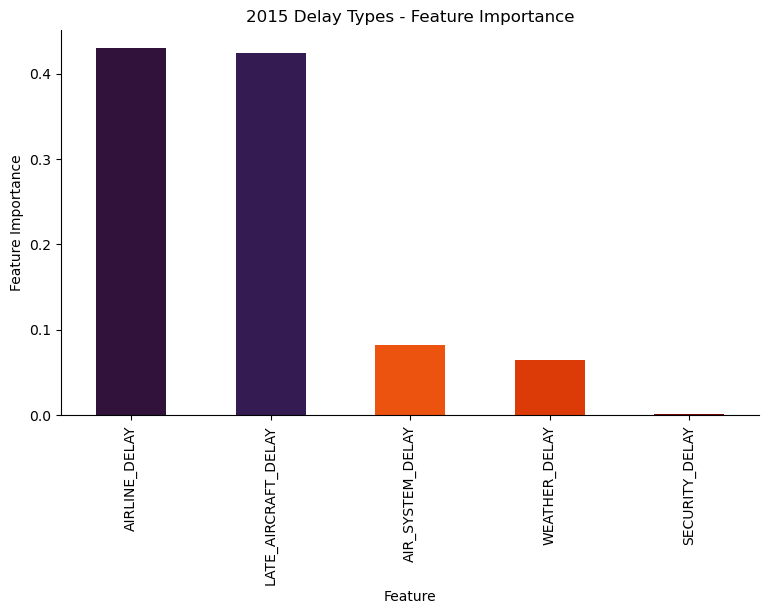

In [355]:
# Generate the bar plot
plt.figure(figsize=(9, 5))
# 1. Normalize values to [0, 1] for the colormap
norm = plt.Normalize(f_imp.min(), f_imp.max())

# 2. Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm')
cmap = plt.get_cmap('turbo_r')

# 3. Map values to colors
colors = cmap(norm(f_imp))

f_imp.plot.bar(color = colors, title='2015 Delay Types - Feature Importance')
plt.xlabel('Feature')
plt.ylabel('Feature Importance');

In [357]:
y_preds = final_model.predict(X_test)
test_RMSE = root_mean_squared_error(y_test, y_preds)
print('RMSE of our optimized model on the test set:', f"{test_RMSE:.2f}")

RMSE of our optimized model on the test set: 0.23


Findings from Random Forest Model (2015):

- Model we ran was optimized for n_estimators on k-fold cross validation), using the 5 special delay types as input and DEPARTURE_DELAY as our target (we're gonna stick with this from here on)
- The two variables with the highest feature importance on a model (test RMSE = 0.23) were LATE_AIRCRAFT_DELAY and AIRLINE_DELAY. Should be noted that the feature importances of the variables our model are in the exact same order as their correlations with the target variable
- RMSE of the RF was slightly better than the regular linear regression, likely due to optimization of the n_estimators hyperparameter

OVERALL Figures to Use:

- Feature importance of RF